[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shuishen112/neural-networks/blob/main/language_models/09_names_vae.ipynb)

# LM 9 — A sequence VAE for names

*Companion to Lecture 9 — Autoencoders and Variational Autoencoders.*

Every language model in this track so far was **purely autoregressive**: it factorises
$p(\mathbf x)=\prod_i p(x_i\mid x_{<i})$ and has no explicit "plan" for the whole string.
Here we give the model a **global latent code** $\mathbf z$: an encoder compresses a whole
name into a vector, and an autoregressive decoder writes the name *conditioned on* that
vector (Bowman et al., 2016, "Generating sentences from a continuous space"). This is the
simplest way to obtain a **continuous space of sentences** in which we can sample,
reconstruct and interpolate, and it is the place where the most famous failure of
latent-variable language models shows up: **posterior collapse**.

> **Language-model track:** 1 Bigram · 2 MLP LM · 3 Training dynamics · 4 PyTorch · 5 Word-level & regularisation · 6 WaveNet · 7 Char-RNN · 8 GPT · **9 Sequence VAE** · 10 Diffusion LM

**Plan.** (1) data as fixed-length padded strings; (2) the model: GRU encoder → $(\boldsymbol\mu,\log\boldsymbol\sigma^2)$ → GRU decoder;
(3) train it naively and watch the KL term die; (4) the classic fixes: KL annealing, character
dropout, free bits; (5) what the latent space gives us: sampling, reconstruction,
interpolation, a PCA map; (6) turning the ELBO into a likelihood we can compare with the rest of the track.

In [1]:
import math
import random
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.decomposition import PCA

torch.manual_seed(0)
torch.set_num_threads(2)
device = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True
print("device:", device, "| torch", torch.__version__)

device: cpu | torch 2.14.1+cpu


In [2]:
from pathlib import Path
import urllib.request

def load_text(name):
    """Load a corpus from ../data (repository checkout) or download it (e.g. on Colab)."""
    for folder in (Path("data"), Path("../data")):
        if (folder / name).exists():
            return (folder / name).read_text(encoding="utf-8")
    url = f"https://raw.githubusercontent.com/shuishen112/neural-networks/main/data/{name}"
    return urllib.request.urlopen(url).read().decode("utf-8")

## 1. Names as fixed-length strings

We use the track's standard split (shuffle with `random.Random(42)`, 80/10/10) and
vocabulary (`"."` = 0, `a`–`z` = 1–26). The encoder wants to read a *whole* name at once,
so we store every name as a row of a fixed width $L=16$: the letters, then `"."` repeated
until the end. The longest name has 15 letters, so every row contains at least one `"."`,
which plays the role of the **end token**.

```
e m m a . . . . . . . . . . . .      target  x_1 … x_16   (positions after the first "." are ignored)
. e m m a . . . . . . . . . . .      decoder input: shifted right, "." = start token
```

For the likelihood we count exactly the tokens an autoregressive model of the track predicts:
the $n$ letters **plus the end token**, i.e. $n+1$ predictions per name. Everything after the
first `"."` is masked out of the loss.

In [3]:
words = [w.strip() for w in load_text("names.txt").splitlines() if w.strip()]
random.Random(42).shuffle(words)
n1, n2 = int(0.8 * len(words)), int(0.9 * len(words))
train_words, val_words, test_words = words[:n1], words[n1:n2], words[n2:]

chars = sorted(set("".join(words)))
stoi = {c: i + 1 for i, c in enumerate(chars)}
stoi["."] = 0
itos = {i: c for c, i in stoi.items()}
V = len(stoi)                      # 27
L = 16                             # fixed width: max name length (15) + at least one "."
BLANK = V                          # extra decoder-input index used by character dropout (§4)
assert V == 27 and itos[0] == "." and itos[1] == "a" and itos[26] == "z"
assert max(len(w) for w in words) < L

def encode(w):
    return [stoi[c] for c in w] + [0] * (L - len(w))

def to_name(ids):
    """Inverse of encode: read characters up to the first '.'."""
    return "".join(itos[i] for i in ids).split(".")[0]

def to_tensor(ws):
    return torch.tensor([encode(w) for w in ws], dtype=torch.long, device=device)

Xtr, Xva, Xte = to_tensor(train_words), to_tensor(val_words), to_tensor(test_words)
assert all(to_name(encode(w)) == w for w in words)            # tokeniser round trip
assert Xtr.shape == (len(train_words), L) and Xtr.dtype == torch.long
train_set = set(train_words)

def n_tokens(X):
    """Number of predicted tokens: letters + one end token per name."""
    return int((X != 0).sum().item() + X.shape[0])

print(f"{len(train_words)} train / {len(val_words)} val / {len(test_words)} test names")
print("example row:", Xtr[0].tolist(), "->", to_name(Xtr[0].tolist()))
print("tokens per name (incl. end):", n_tokens(Xva) / len(Xva))

25626 train / 3203 val / 3204 test names
example row: [25, 21, 8, 5, 14, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0] -> yuheng
tokens per name (incl. end): 7.073056509522323


## 2. The model

The generative story is the one from Lecture 9, with a different decoder:

$$\mathbf z\sim\mathcal N(\mathbf 0, I_k),\qquad p_\theta(\mathbf x\mid\mathbf z)=\prod_{i=1}^{n+1}p_\theta(x_i\mid x_{<i},\mathbf z).$$

The decoder is a **GRU language model** (LM 7 used an LSTM; a GRU is the same idea with one
state vector) that sees $\mathbf z$ twice: as its initial hidden state
$\mathbf h_0=\tanh(W\mathbf z+\mathbf b)$, and concatenated to the embedding of every input
character. The **encoder** $q_\phi(\mathbf z\mid\mathbf x)=\mathcal N(\boldsymbol\mu_\phi(\mathbf x),\operatorname{diag}\boldsymbol\sigma^2_\phi(\mathbf x))$
is a bidirectional GRU that reads the padded name; its two final hidden states are mapped to
$\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$. The negative ELBO per name is

$$-\mathcal L(\mathbf x)=\underbrace{-\mathbb E_{q_\phi}\Big[\sum_{i=1}^{n+1}\log p_\theta(x_i\mid x_{<i},\mathbf z)\Big]}_{\text{reconstruction (cross-entropy, teacher forcing)}}+\underbrace{\tfrac12\sum_{j=1}^k\big(\mu_j^2+\sigma_j^2-1-\log\sigma_j^2\big)}_{\mathrm{KL}(q_\phi(\mathbf z\mid\mathbf x)\,\Vert\,p(\mathbf z))},$$

estimated with one reparameterised sample $\mathbf z=\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\epsilon$.
As in the lecture we **sum** (not average) over characters and latent dimensions, so the two
terms are in the same units: nats per name.

In [4]:
class NameVAE(nn.Module):
    def __init__(self, k=16, emb=32, h_enc=64, h_dec=128):
        super().__init__()
        self.k = k
        self.enc_emb = nn.Embedding(V, emb)
        self.enc_rnn = nn.GRU(emb, h_enc, batch_first=True, bidirectional=True)
        self.to_stats = nn.Linear(2 * h_enc, 2 * k)
        self.dec_emb = nn.Embedding(V + 1, emb)            # +1: the BLANK token for character dropout
        self.z_to_h = nn.Linear(k, h_dec)
        self.dec_rnn = nn.GRU(emb + k, h_dec, batch_first=True)
        self.out = nn.Linear(h_dec, V)

    def encode(self, x):                                   # x: (B, L) long
        _, h = self.enc_rnn(self.enc_emb(x))               # h: (2, B, h_enc)  (2 = two directions)
        stats = self.to_stats(torch.cat([h[0], h[1]], dim=-1))
        mu, logvar = stats.chunk(2, dim=-1)                # (B, k) each
        return mu, logvar

    def decode(self, z, inp, h=None):
        """z: (B, k), inp: (B, T) long decoder inputs -> logits (B, T, V), new hidden state (1, B, h_dec)."""
        if h is None:
            h = torch.tanh(self.z_to_h(z)).unsqueeze(0)    # (1, B, h_dec)
        e = self.dec_emb(inp)                              # (B, T, emb)
        zz = z.unsqueeze(1).expand(-1, inp.shape[1], -1)   # (B, T, k)
        o, h = self.dec_rnn(torch.cat([e, zz], dim=-1), h)
        return self.out(o), h

def decoder_inputs(x):
    """Shift right and put the start token '.' (index 0) in front."""
    return torch.cat([torch.zeros_like(x[:, :1]), x[:, :-1]], dim=1)

def valid_mask(x):
    """True at the letters and at the first '.', i.e. the n+1 positions we score."""
    lengths = (x != 0).sum(1)
    return torch.arange(x.shape[1], device=x.device).unsqueeze(0) <= lengths.unsqueeze(1)

def rec_nll(logits, x, mask):
    """-log p(x | z) per name (sum over the scored positions)."""
    ce = F.cross_entropy(logits.reshape(-1, V), x.reshape(-1), reduction="none").view(x.shape)
    return (ce * mask).sum(1)

def gaussian_kl(mu, logvar):
    """KL(N(mu, diag exp(logvar)) || N(0, I)) per dimension, shape (B, k)."""
    return 0.5 * (mu.pow(2) + logvar.exp() - 1.0 - logvar)

model = NameVAE().to(device)
xb = Xtr[:5]
mu, logvar = model.encode(xb)
logits, h = model.decode(mu, decoder_inputs(xb))
print("mu", tuple(mu.shape), "| logits", tuple(logits.shape), "| hidden", tuple(h.shape))
print("scored positions of", repr(train_words[0]), ":", valid_mask(xb)[0].int().tolist())
assert logits.shape == (5, L, V) and mu.shape == (5, model.k)
assert valid_mask(xb).sum().item() == n_tokens(xb)
print(f"{sum(p.numel() for p in model.parameters())} parameters")

mu (5, 16) | logits (5, 16, 27) | hidden (1, 5, 128)
scored positions of 'yuheng' : [1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]
117531 parameters


## 3. Training, and four ways to do it

One training function covers all the variants we want to compare:

* **plain**: minimise the negative ELBO from the first step ($\beta=1$);
* **KL annealing** (Bowman et al.): minimise $\text{rec}+\beta\,\mathrm{KL}$ with $\beta$ rising linearly
  from $0$ to $1$ over the first half of training, then the true ELBO;
* **character dropout** ("word dropout" in Bowman et al.): replace a random fraction of the
  decoder's *input* characters by a `BLANK` token (the targets are unchanged), so the decoder
  cannot rely on its history alone and has an incentive to read $\mathbf z$;
* **free bits** (Kingma et al., 2016): do not penalise the first $\lambda$ nats of KL per latent
  dimension, $\sum_j\max\big(\lambda,\ \overline{\mathrm{KL}}_j\big)$ where $\overline{\mathrm{KL}}_j$ is the batch-average KL of dimension $j$.

Only the plain variant optimises the ELBO all the way; the others change the objective during
training. We therefore **evaluate** every model with the true ELBO ($\beta=1$, no dropout, no free bits).

In [5]:
BATCH, EPOCHS, LR = 256, 6, 3e-3

def train_vae(beta_warmup=0.0, char_dropout=0.0, free_bits=0.0, epochs=EPOCHS, seed=0):
    torch.manual_seed(seed)
    model = NameVAE().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    steps_per_epoch = math.ceil(len(Xtr) / BATCH)
    n_steps = epochs * steps_per_epoch
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_steps, eta_min=LR / 10)
    warm = int(beta_warmup * n_steps)
    hist = {"rec": [], "kl": [], "beta": []}             # per step, in nats per name
    step = 0
    for epoch in range(epochs):
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), BATCH):
            x = Xtr[perm[i:i + BATCH]]
            beta = min(1.0, step / warm) if warm > 0 else 1.0
            mu, logvar = model.encode(x)
            z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
            inp = decoder_inputs(x)
            if char_dropout > 0:
                drop = torch.rand(inp.shape, device=device) < char_dropout
                drop[:, 0] = False                         # always keep the start token
                inp = inp.masked_fill(drop, BLANK)
            logits, _ = model.decode(z, inp)
            rec = rec_nll(logits, x, valid_mask(x)).mean()
            kl_dims = gaussian_kl(mu, logvar).mean(0)      # (k,) average KL per dimension
            kl = kl_dims.sum()
            kl_term = torch.clamp(kl_dims, min=free_bits).sum() if free_bits > 0 else kl
            loss = rec + beta * kl_term
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()
            hist["rec"].append(rec.item()); hist["kl"].append(kl.item()); hist["beta"].append(beta)
            step += 1
    return model, hist

@torch.no_grad()
def evaluate(model, X, seed=123):
    """True ELBO (beta = 1, one z sample per name). Returns a dict of summary numbers."""
    torch.manual_seed(seed)
    rec_sum, kl_sum, mus = 0.0, 0.0, []
    for i in range(0, len(X), 1024):
        x = X[i:i + 1024]
        mu, logvar = model.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        logits, _ = model.decode(z, decoder_inputs(x))
        rec_sum += rec_nll(logits, x, valid_mask(x)).sum().item()
        kl_sum += gaussian_kl(mu, logvar).sum().item()
        mus.append(mu)
    mus = torch.cat(mus)
    ntok = n_tokens(X)
    return {"rec/char": rec_sum / ntok, "KL/name": kl_sum / len(X),
            "-ELBO/char": (rec_sum + kl_sum) / ntok,
            "active": int((mus.var(0) > 0.01).sum().item())}

### 3.1 The naive VAE and posterior collapse

First the textbook objective, $\beta=1$ from the start.

(19 s)  val: {'rec/char': 2.044, 'KL/name': 0.063, '-ELBO/char': 2.053, 'active': 2}


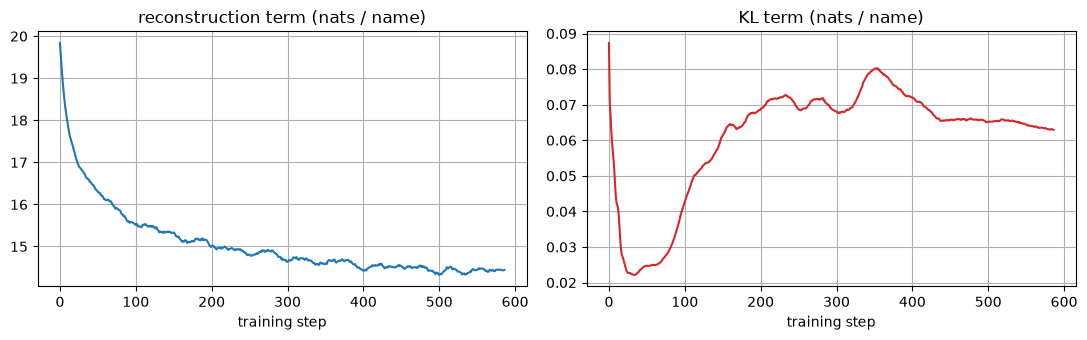

In [6]:
t0 = time.time()
vae_plain, hist_plain = train_vae()
res_plain = evaluate(vae_plain, Xva)
print(f"({time.time() - t0:.0f} s)  val:", {k: round(v, 3) for k, v in res_plain.items()})

def smooth(v, w=20):
    v = np.asarray(v, dtype=float)
    return np.convolve(v, np.ones(w) / w, mode="valid")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(smooth(hist_plain["rec"])); axes[0].set_title("reconstruction term (nats / name)")
axes[1].plot(smooth(hist_plain["kl"]), color="C3"); axes[1].set_title("KL term (nats / name)")
for ax in axes:
    ax.set_xlabel("training step")
plt.tight_layout(); plt.show()

Typically the KL term may rise briefly at the very beginning and is then driven to (nearly)
**zero**, where it stays. The encoder outputs
$q_\phi(\mathbf z\mid\mathbf x)\approx\mathcal N(\mathbf 0,I)$ for *every* name, the decoder
learns to ignore $\mathbf z$, and the "VAE" is just a GRU language model with some useless
noise as an extra input. This is **posterior collapse**. Why does gradient descent go there?

* At initialisation $\mathbf z$ carries no useful information (the encoder is random), so the
  decoder learns to predict from the history $x_{<i}$, which is *very* informative for text.
* Every nat of information in $\mathbf z$ costs one nat of KL. Early on that information is
  worth less than a nat of reconstruction, so the cheapest move is to shut the encoder down.
* Once $q_\phi=p(\mathbf z)$, the gradient that would teach the decoder to use $\mathbf z$ is
  tiny (the code is pure noise), and we are stuck in a stable, poor local optimum.

The more powerful the autoregressive decoder, the worse this gets: an AR decoder can model
$p(\mathbf x)$ perfectly well **on its own**, so the ELBO does not *need* the latent variable.
(A useful way to see it: with a perfect decoder, $\mathrm{KL}(q\Vert p)=0$ *is* the optimum of
the ELBO, since the gap $\mathrm{KL}(q_\phi(\mathbf z\mid\mathbf x)\Vert p_\theta(\mathbf z\mid\mathbf x))$ vanishes when $\mathbf z$ and $\mathbf x$ are independent.)

### 3.2 The fixes

Now the three remedies (the table also contains the plain run). The second half of training is
identical for all annealed runs: $\beta=1$, the real ELBO.

annealing                  (18 s)


annealing + char dropout   (17 s)


free bits (λ=0.25)         (17 s)


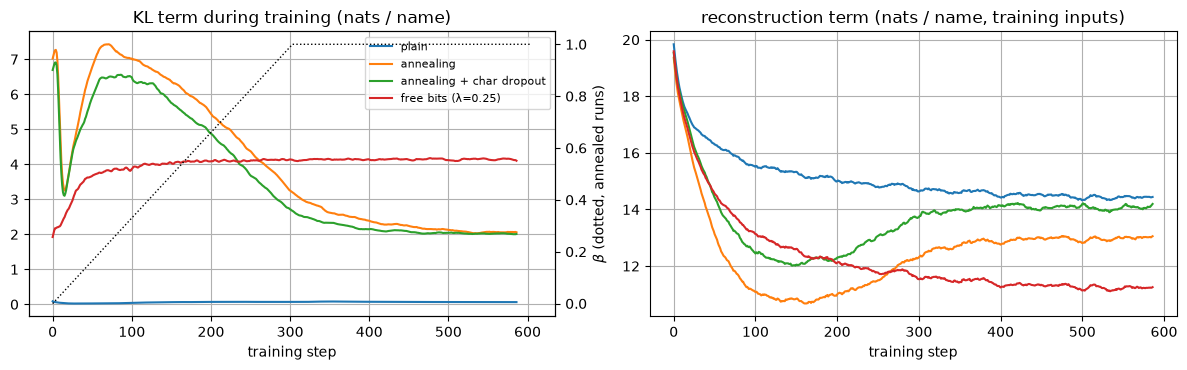

In [7]:
SETTINGS = {
    "annealing": dict(beta_warmup=0.5),
    "annealing + char dropout": dict(beta_warmup=0.5, char_dropout=0.3),
    "free bits (λ=0.25)": dict(free_bits=0.25),
}
models, hists, results = {"plain": vae_plain}, {"plain": hist_plain}, {"plain": res_plain}
for name, kw in SETTINGS.items():
    t0 = time.time()
    models[name], hists[name] = train_vae(**kw)
    results[name] = evaluate(models[name], Xva)
    print(f"{name:26s} ({time.time() - t0:.0f} s)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for i, name in enumerate(models):
    axes[0].plot(smooth(hists[name]["kl"]), label=name, color=f"C{i}")
    axes[1].plot(smooth(hists[name]["rec"]), label=name, color=f"C{i}")
ax2 = axes[0].twinx(); ax2.grid(False)
ax2.plot(hists["annealing"]["beta"], "k:", lw=1); ax2.set_ylabel(r"$\beta$ (dotted, annealed runs)")
axes[0].set_title("KL term during training (nats / name)"); axes[0].legend(fontsize=8)
axes[1].set_title("reconstruction term (nats / name, training inputs)")
for ax in axes:
    ax.set_xlabel("training step")
plt.tight_layout(); plt.show()

Before we read the table, one more number per model: **reconstruction accuracy**. Encode a
validation name to its posterior mean $\boldsymbol\mu_\phi(\mathbf x)$, decode **greedily**
(argmax at every step) and check whether we get the same name back. A collapsed model decodes
every code to (roughly) the same most-likely name, so its accuracy is close to zero.

In [8]:
@torch.no_grad()
def decode_z(model, z, sample=False, temperature=1.0):
    """Run the decoder from latent codes z (B, k); greedy (argmax) or sampled. Returns names."""
    B = z.shape[0]
    tok = torch.zeros(B, 1, dtype=torch.long, device=z.device)      # start token "."
    h, out = None, []
    for _ in range(L):
        logits, h = model.decode(z, tok, h)                          # (B, 1, V)
        logits = logits[:, -1]
        if sample:
            tok = torch.multinomial(F.softmax(logits / temperature, dim=-1), 1)   # (B, 1)
        else:
            tok = logits.argmax(dim=-1, keepdim=True)                # (B, 1)
        out.append(tok)
    ids = torch.cat(out, dim=1).cpu().tolist()                       # (B, L)
    return [to_name(r) for r in ids]

@torch.no_grad()
def reconstruct(model, ws):
    mu, _ = model.encode(to_tensor(ws))
    return decode_z(model, mu)

def recon_accuracy(model, ws):
    rec = reconstruct(model, ws)
    return float(np.mean([a == b for a, b in zip(rec, ws)]))

for name in models:
    results[name]["recon acc"] = recon_accuracy(models[name], val_words)

print(f"{'setting':26s} {'rec/char':>9s} {'KL/name':>8s} {'-ELBO/char':>11s} {'active':>7s} {'recon acc':>10s}")
for name, r in results.items():
    print(f"{name:26s} {r['rec/char']:9.3f} {r['KL/name']:8.2f} {r['-ELBO/char']:11.3f} "
          f"{r['active']:5d}/{models[name].k:<2d} {r['recon acc']:9.1%}")
print("\n(validation set; rec and -ELBO in nats per character incl. the end token, KL in nats per name)")

setting                     rec/char  KL/name  -ELBO/char  active  recon acc
plain                          2.044     0.06       2.053     2/16      0.0%
annealing                      1.831     2.06       2.122    14/16      0.7%
annealing + char dropout       1.873     1.98       2.153    15/16      0.4%
free bits (λ=0.25)             1.587     4.15       2.173    16/16      6.4%

(validation set; rec and -ELBO in nats per character incl. the end token, KL in nats per name)


**How to read the table.**

* **KL/name** is the *rate*: how many nats the code carries about each name. The plain model is
  typically at (or very near) zero, with no active units and near-zero reconstruction accuracy.
* The fixes buy a non-trivial rate: the code now encodes several nats per name, a number of latent
  dimensions become active, and greedy decoding from $\boldsymbol\mu$ starts to recover names
  exactly, though with a code of a few nats only a small fraction (a perfect code for a name needs
  roughly 10–15 nats). Free bits gives the largest KL here because it *guarantees* a minimum rate per
  dimension; character dropout works more indirectly — a decoder that cannot trust its own history
  needs $\mathbf z$ more — and its effect grows with longer training and higher dropout rates.
* **−ELBO/char** is the honest likelihood bound. Do not be surprised if the collapsed model is
  *as good or better* here: putting information in $\mathbf z$ costs exactly as many nats of KL as it
  saves in reconstruction at best, and an imperfect encoder usually loses a bit. **The ELBO does not reward
  a useful latent space.** That is the central tension of VAEs for text: we use them for the
  *representation*, not for the likelihood.

Exact numbers depend on the seed and the short training run; the qualitative picture is robust.
For the rest of the notebook we use the **annealing + character dropout** model, the recipe of Bowman et al.

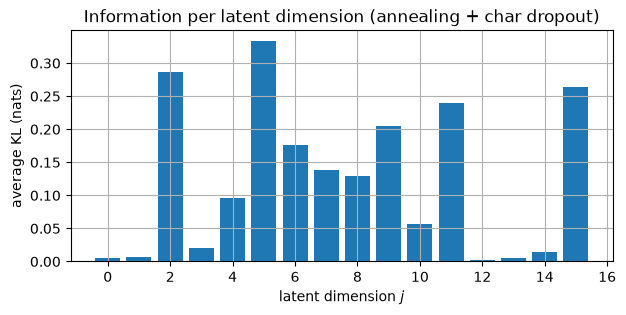

In [9]:
vae = models["annealing + char dropout"]
with torch.no_grad():
    mu_va, logvar_va = vae.encode(Xva)
    kl_dims = gaussian_kl(mu_va, logvar_va).mean(0).cpu().numpy()
plt.figure(figsize=(7, 3))
plt.bar(range(vae.k), kl_dims)
plt.xlabel("latent dimension $j$"); plt.ylabel("average KL (nats)")
plt.title("Information per latent dimension (annealing + char dropout)"); plt.show()

## 4. What a latent space of names gives us

### 4.1 Sampling from the prior

Draw $\mathbf z\sim\mathcal N(\mathbf 0,I)$ and decode. With **greedy** decoding the name is a
deterministic function of $\mathbf z$, so every bit of variety comes from the latent code; with
**sampling** the decoder adds its own randomness on top.

In [10]:
torch.manual_seed(1)
z_prior = torch.randn(200, vae.k, device=device)
greedy_names = decode_z(vae, z_prior)
sampled_names = decode_z(vae, z_prior, sample=True)
print("greedy  :", " ".join(greedy_names[:20]))
print("sampled :", " ".join(sampled_names[:20]))
for label, ns in [("greedy", greedy_names), ("sampled", sampled_names)]:
    ns_ok = [n for n in ns if n]
    print(f"{label:8s} distinct {len(set(ns)) / len(ns):5.1%} | novel (not in train) "
          f"{np.mean([n not in train_set for n in ns_ok]):5.1%} | mean length {np.mean([len(n) for n in ns]):.2f}"
          f" (data {np.mean([len(w) for w in train_words]):.2f})")

# Same z, several decoder samples: what does z pin down, and what is left to the decoder?
z_one = torch.randn(1, vae.k, device=device).repeat(8, 1)
print("\none z, 8 sampled decodings:", " ".join(decode_z(vae, z_one, sample=True)))

greedy  : remari ander elianna halen jonnelle mari aleshan alis mishamiah arian charlee aris alariah jaylee shaylen anari elishan jashir arian eliste
sampled : rmelus hrenkey cdiona jaeni kuenmer dilia aleishy alivon vaijana yansl ahselynn aelin aamerah wyven htylex aida gobtolle jobina acari eviste
greedy   distinct 88.0% | novel (not in train) 47.0% | mean length 5.88 (data 6.13)
sampled  distinct 100.0% | novel (not in train) 91.0% | mean length 6.29 (data 6.13)

one z, 8 sampled decodings: swre kiala kote henzio hamiat aafhor jonai tademi


Greedy decoding from different prior samples should give a varied list of plausible names; the
*collapsed* model would give the same name for every $\mathbf z$ (try it: `decode_z(vae_plain, z_prior)`).
Decoding one fixed $\mathbf z$ several times with sampling typically gives names that share
features (start, length, ending): the code holds the "gist", the decoder fills in details.

### 4.2 Reconstruction

In [11]:
examples = val_words[:12]
for w, r in zip(examples, reconstruct(vae, examples)):
    print(f"{w:>12s} -> {r:<12s} {'✓' if w == r else ''}")
acc_va = recon_accuracy(vae, val_words)
print(f"\nexact reconstruction accuracy on validation names: {acc_va:.1%}")
print(f"same for the collapsed plain model:              {results['plain']['recon acc']:.1%}")
assert len(reconstruct(vae, examples)) == len(examples)

        amay -> amari        
      aytana -> analia       
      jenevi -> jeniel       
       zylen -> daylen       
        naim -> naila        
     milanni -> maliana      
      eriyah -> emira        
      keshan -> kenisa       
    carolina -> cariston     
        toni -> tori         
       nolan -> nila         
     michela -> mariel       



exact reconstruction accuracy on validation names: 0.4%
same for the collapsed plain model:              0.0%


Errors are rarely random: the reconstruction usually keeps the first letters, the length and the
ending, and substitutes a similar, often more frequent, name. A rate of a few nats per name
is simply not enough to pin down every one of tens of thousands of names (identifying one name out of
~30 000 would take $\ln 30\,000\approx10$ nats).

### 4.3 Interpolation: a continuous path between two names

Bowman et al.'s signature experiment ("homotopies"): encode two names, walk along the straight line
$\mathbf z(\lambda)=(1-\lambda)\boldsymbol\mu_a+\lambda\boldsymbol\mu_b$ and decode greedily at each point.
A smooth latent space gives a sequence of *valid* names that gradually morph from one into the other.

In [12]:
@torch.no_grad()
def interpolate(model, a, b, n=8):
    mu, _ = model.encode(to_tensor([a, b]))
    lam = torch.linspace(0, 1, n, device=device).unsqueeze(1)          # (n, 1)
    return decode_z(model, (1 - lam) * mu[0] + lam * mu[1])

for a, b in [("mia", "alexander"), ("john", "isabella"), ("zoe", "maximilian"), ("emma", "oliver")]:
    print(" → ".join(interpolate(vae, a, b)))

mari → maria → maria → maria → aliana → alisha → aleigh → alesta
joni → jonia → janie → janie → samira → salian → analie → analie
jore → daylen → daylin → dailee → mariel → mariel → mariel → marista
emira → emira → emira → emira → elian → elian → elisha → elista


Typically the path changes length and ending gradually and passes through real-looking names
(often actual names from the data). The endpoints themselves may not be reproduced exactly, which is
the reconstruction error of §4.2.

### 4.4 A map of the latent space

Project the posterior means of all validation names onto their first two principal components (PCA,
Lecture 9 §1) and colour them by simple properties of the name.

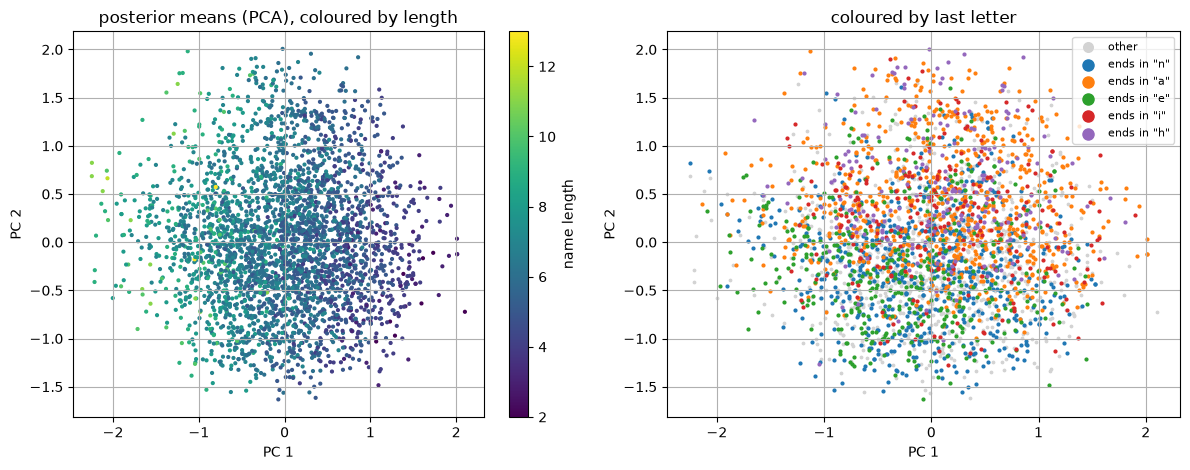

In [13]:
mu_np = mu_va.cpu().numpy()
P = PCA(n_components=2).fit_transform(mu_np)
lengths = np.array([len(w) for w in val_words])
last = np.array([w[-1] for w in val_words])
top_last = [c for c, _ in Counter(last).most_common(5)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sc = axes[0].scatter(P[:, 0], P[:, 1], c=lengths, cmap="viridis", s=4)
plt.colorbar(sc, ax=axes[0], label="name length")
axes[0].set_title("posterior means (PCA), coloured by length")
other = ~np.isin(last, top_last)
axes[1].scatter(P[other, 0], P[other, 1], s=3, c="lightgray", label="other")
for i, c in enumerate(top_last):
    sel = last == c
    axes[1].scatter(P[sel, 0], P[sel, 1], s=4, color=f"C{i}", label=f'ends in "{c}"')
axes[1].legend(markerscale=4, fontsize=8); axes[1].set_title("coloured by last letter")
for ax in axes:
    ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
plt.tight_layout(); plt.show()

Without any labels, the encoder organises names by surface properties that matter for
reconstruction: length usually varies smoothly along one direction and frequent endings
(`-a`, `-n`, `-e`, `-y`, ...) form overlapping regions. This is the idea behind **sentence
embeddings**: a fixed-size vector that summarises a variable-length string.

## 5. How good is the VAE as a language model?

Every model in the track reports $-\frac1N\sum\log p(\text{name})$ in nats per character.
The VAE cannot compute $\log p_\theta(\mathbf x)=\log\int p_\theta(\mathbf x\mid\mathbf z)p(\mathbf z)\,d\mathbf z$ exactly,
but Lecture 9 showed that the ELBO is a **lower bound** on it, so

$$\text{NLL}(\mathbf x)=-\log p_\theta(\mathbf x)\;\le\;-\mathcal L(\mathbf x)=\text{rec}+\mathrm{KL}.$$

The −ELBO is an **upper bound on the NLL**: the true NLL of our model is at most this value. A
tighter bound is the **importance-weighted bound** (IWAE; Burda et al., 2016). Draw
$\mathbf z_1,\dots,\mathbf z_K\sim q_\phi(\mathbf z\mid\mathbf x)$ and average the importance weights
*inside* the log:

$$\mathcal L_K(\mathbf x)=\mathbb E\left[\log\frac1K\sum_{k=1}^K\frac{p_\theta(\mathbf x\mid\mathbf z_k)\,p(\mathbf z_k)}{q_\phi(\mathbf z_k\mid\mathbf x)}\right],
\qquad \mathcal L=\mathcal L_1\le\mathcal L_K\le\mathcal L_{K+1}\le\log p_\theta(\mathbf x),$$

with $\mathcal L_K\to\log p_\theta(\mathbf x)$ as $K\to\infty$ (the bound follows from Jensen's inequality, since
the average weight is an unbiased estimate of $p_\theta(\mathbf x)$). We compute $\log$ of an average of
exponentials stably with `torch.logsumexp`. All three densities are cheap: $p_\theta(\mathbf x\mid\mathbf z)$ is the
decoder's likelihood, and $p$, $q$ are diagonal Gaussians.

In [14]:
LOG2PI = math.log(2 * math.pi)

@torch.no_grad()
def iwae_nll(model, X, K, seed=0, chunk=1024):
    """-L_K in nats per character (upper bound on the NLL; K = 1 is the ordinary -ELBO)."""
    torch.manual_seed(seed)
    total = 0.0
    for i in range(0, len(X), chunk):
        x = X[i:i + chunk]
        mu, logvar = model.encode(x)
        std = torch.exp(0.5 * logvar)
        inp, mask = decoder_inputs(x), valid_mask(x)
        logw = []
        for _ in range(K):
            z = mu + std * torch.randn_like(std)
            logits, _ = model.decode(z, inp)
            log_px_z = -rec_nll(logits, x, mask)                                  # (B,)
            log_pz = (-0.5 * (z.pow(2) + LOG2PI)).sum(1)                          # (B,)
            log_qz = (-0.5 * (((z - mu) / std).pow(2) + logvar + LOG2PI)).sum(1)  # (B,)
            logw.append(log_px_z + log_pz - log_qz)
        logw = torch.stack(logw)                                                  # (K, B)
        total += (torch.logsumexp(logw, dim=0) - math.log(K)).sum().item()
    return -total / n_tokens(X)

t0 = time.time()
Ks = [1, 10, 50]
bounds = {K: iwae_nll(vae, Xva, K) for K in Ks}
for K, b in bounds.items():
    print(f"K = {K:3d}:  -L_K = {b:.4f} nats/char")
print(f"plain (collapsed) model, K = 1: {iwae_nll(vae_plain, Xva, 1):.4f} nats/char   ({time.time() - t0:.0f} s)")
assert all(math.isfinite(b) for b in bounds.values())
assert bounds[50] < math.log(27)          # far better than uniform guessing

K =   1:  -L_K = 2.1468 nats/char
K =  10:  -L_K = 2.1306 nats/char
K =  50:  -L_K = 2.1289 nats/char
plain (collapsed) model, K = 1: 2.0510 nats/char   (4 s)


The bound tightens as $K$ grows (up to Monte-Carlo noise), which means our encoder is not the exact
posterior; the remaining gap to the true NLL is unknown but shrinks with $K$. For the track-wide
comparison we report the tightest bound we computed. Remember what kind of number it is: an **upper bound**
on the VAE's NLL, comparable in units (nats per character, end token included) to the exact NLLs of
LM 1–8, and typically in the same range as a well-trained MLP or RNN LM, since the decoder *is* an RNN LM.

In [15]:
print(f"val NLL (nats/char): {bounds[Ks[-1]]:.3f}   (upper bound: importance-weighted ELBO, K = {Ks[-1]})")

val NLL (nats/char): 2.129   (upper bound: importance-weighted ELBO, K = 50)


## From here to LLMs

* **Latent-variable vs purely autoregressive LMs.** Large language models are purely autoregressive:
  $p(\mathbf x)=\prod_i p(x_i\mid x_{<i})$, exact likelihood, no latent code. This notebook shows one reason:
  for text, a strong AR decoder makes a global latent variable unnecessary *for likelihood*, and the
  training signal actively pushes it towards collapse. Sentence-level VAEs (Bowman et al.;
  Optimus, Li et al., 2020, which put a BERT encoder and a GPT-2 decoder around a latent code) remain a
  research tool for controllable generation and interpolation, not the backbone of LLMs.
* **Sentence embeddings.** The useful by-product of our VAE is $\boldsymbol\mu_\phi(\mathbf x)$: a fixed-size
  vector for a variable-length string. Modern systems obtain such vectors differently, by pooling a
  Transformer encoder trained with contrastive objectives (Sentence-BERT, E5, and the embedding
  models behind retrieval-augmented generation), but they serve the same purpose: similar text, nearby vectors.
* **Where VAEs are everywhere today: as the autoencoder of latent diffusion.** Stable Diffusion and many
  video and audio generators compress the data with a (KL-regularised) VAE and run diffusion in its
  latent space (Rombach et al., 2022; Lecture 10 §6.3). There the KL weight is tiny (the code is
  meant to carry almost everything) and posterior collapse is not an issue because the decoder is not autoregressive.
* **Discrete bottlenecks.** VQ-VAEs (van den Oord et al., 2017) replace the Gaussian code with a
  sequence of discrete codebook entries, which an autoregressive Transformer can then model like text.
  That is how audio tokenizers (neural codecs) and image tokenizers turn speech and pictures into tokens for multimodal LLMs.
* **The ELBO keeps coming back.** The bound $\log p\ge\mathbb E_q[\log p(\mathbf x\mid\mathbf z)]-\mathrm{KL}$ is also
  the training objective of diffusion models, including the **diffusion language model** of the next
  notebook, whose likelihood is again reported as an upper bound.

## Try it yourself

1. Make the decoder weaker (e.g. only `z → h0`, no concatenation; or a smaller `h_dec`) and stronger
   (two GRU layers). How does the KL of the plain model change? Does annealing still help?
2. Vary the character-dropout rate from 0 to 1. At rate 1 the decoder is a "bag of positions" model
   that must get everything from $\mathbf z$: what happens to the KL, the reconstruction accuracy and the −ELBO?
3. Free bits with different $\lambda$: plot the KL per dimension. Does the model use more dimensions
   than with annealing?
4. Replace the linear interpolation by a *spherical* one (slerp), which stays in the high-density shell of
   $\mathcal N(\mathbf 0, I)$. Do the intermediate names look more plausible?
5. Add a binary attribute (e.g. "ends in a vowel") as a conditioning input to the decoder (a CVAE). Can you
   keep $\mathbf z$ fixed and flip the attribute?

**Further reading.**
Bowman, Vilnis, Vinyals, Dai, Jozefowicz & Bengio, "Generating sentences from a continuous space", CoNLL 2016;
Kingma, Salimans, Jozefowicz, Chen, Sutskever & Welling, "Improved variational inference with inverse autoregressive flow", NeurIPS 2016 (free bits);
Burda, Grosse & Salakhutdinov, "Importance weighted autoencoders", ICLR 2016;
Chen et al., "Variational lossy autoencoder", ICLR 2017 (why powerful decoders ignore $\mathbf z$);
He, Spokoyny, Neubig & Berg-Kirkpatrick, "Lagging inference networks and posterior collapse in VAEs", ICLR 2019;
Fu et al., "Cyclical annealing schedule: a simple approach to mitigating KL vanishing", NAACL 2019;
Li et al., "Optimus: organizing sentences via pre-trained modeling of a latent space", EMNLP 2020;
Rombach et al., "High-resolution image synthesis with latent diffusion models", CVPR 2022.